# Tabulation API Example: Superadiabatic Flamelet Models

_This demo is part of Spitfire, with [licensing and copyright info here.](https://github.com/sandialabs/Spitfire/blob/master/license.md)_

_Highlights_

- creating libraries with superadiabatic and/or subadiabatic states using `build_nonadiabatic*` methods in Spitfire
- demonstrating aluminum chemistry nonadiabatic equilibrium  

This example builds nonadiabatic flamelet models that include both superadiabatic and subadiabatic states using heptane and aluminum chemistry. It also demonstrates the use of a heatloss multiplier for nonadiabatic equilibrium.


In [24]:
from spitfire import (ChemicalMechanismSpec, 
                      FlameletSpec,
                      Library,
                      build_nonadiabatic_defect_eq_library, 
                      build_nonadiabatic_defect_transient_slfm_library)
import matplotlib.pyplot as plt
import numpy as np


## Nonadiabatic equilibrium with aluminum chemistry

Below we build four nonadiabatic equilibrum libraries with various features turned on/off. All four use a `stoich_heatloss_multiplier` that helps expand the heatloss dimension of the table. This can be useful for certain chemistries where the heat loss profile of the cooled mixture is not similar to the presumed triangular profile peaking at stoichiometric mixture fraction. Superadiabatic states can be added to the library when specifying a nonzero `superad_dT`. These states are computed through raising the boundary temperatures and solving for equilibrium. Subadiabatic states can also be shifted away from the adiabatic state defined by the `FlameletSpec` class by providing a nonzero `subad_dT`. Fuel and oxidizer temperature differences can be specified separately through a dictionary with `'fuel'` and `'oxy'` keys for both `superad_dT` and `subad_dT`. The number of stoichiometric enthalpy defect points added to the library is controlled through n_defect_st. When including superadiabatic states, this must be a dictionary with `'n_subad'` and `'n_superad'` keys controlling the number of subadiabatic and superadiatic tabulation states, respectively. The adiabatic state with zero stoichiometric enthalpy defect is always included.

The first 'nonad equilibrium' library does not use any boundary temperature shifts. The triangular enthalpy defect profiles have a single degenerate point at a mixture fraction of zero and one. The adiabatic state is defined by the horizontal line at enthalpy defect of zero.

The second library 'incl. superad' adds 3 superadiabatic profiles to the existing subadiabatic states of 'nonad equilibrium'. These are the 3 linear profiles that exist at positive enthalpy defect. The fuel and oxidizer temperatures are shifted by different amounts using a dictionary for `superad_dT`.

The third library 'incl. subad shift' shifts the fuel and oxidizer temperatures (by the same amount `subad_dT`=100 K) prior to performing the subadiabatic solutions. The adiabatic state from 'nonad equilibrium' still exists at enthalpy defect of zero, but the degenerate points at the pure streams are shifted down relative to the adiabatic state.

The fourth library 'incl. both' performs both the superadiabatic solutions of 'incl. superad' and the shifted subadiabatic solutions of 'incl. subad shift'.


In [25]:
mech = ChemicalMechanismSpec(cantera_input='catoire_al2o3.yaml', group_name='gas')
pressure = 101325.
air = mech.stream(stp_air=True)
air.TP = 400., pressure
fuel = mech.stream('TPX', (400., pressure, 'Al:1'))
flamelet_specs = FlameletSpec(mech_spec=mech, oxy_stream=air, fuel_stream=fuel, grid_points=128)

stoich_heatloss_multiplier = 1.7
subad_dT = 100.
superad_dT = {'fuel':3000.-fuel.T, 'oxy':2600.-air.T}
n_defect_st = {'n_subad':5, 'n_superad':3}

l_eq = build_nonadiabatic_defect_eq_library(flamelet_specs, n_defect_st=n_defect_st['n_subad']+1, stoich_heatloss_multiplier=stoich_heatloss_multiplier, verbose=False)

l_both = build_nonadiabatic_defect_eq_library(flamelet_specs, verbose=False, stoich_heatloss_multiplier=stoich_heatloss_multiplier,
                                              n_defect_st=n_defect_st, superad_dT=superad_dT, subad_dT=subad_dT)

l_superad = build_nonadiabatic_defect_eq_library(flamelet_specs, verbose=False, stoich_heatloss_multiplier=stoich_heatloss_multiplier,
                                                 n_defect_st=n_defect_st, superad_dT=superad_dT)

l_subad = build_nonadiabatic_defect_eq_library(flamelet_specs, verbose=False, stoich_heatloss_multiplier=stoich_heatloss_multiplier,
                                                 n_defect_st=n_defect_st['n_subad']+1, subad_dT=subad_dT)


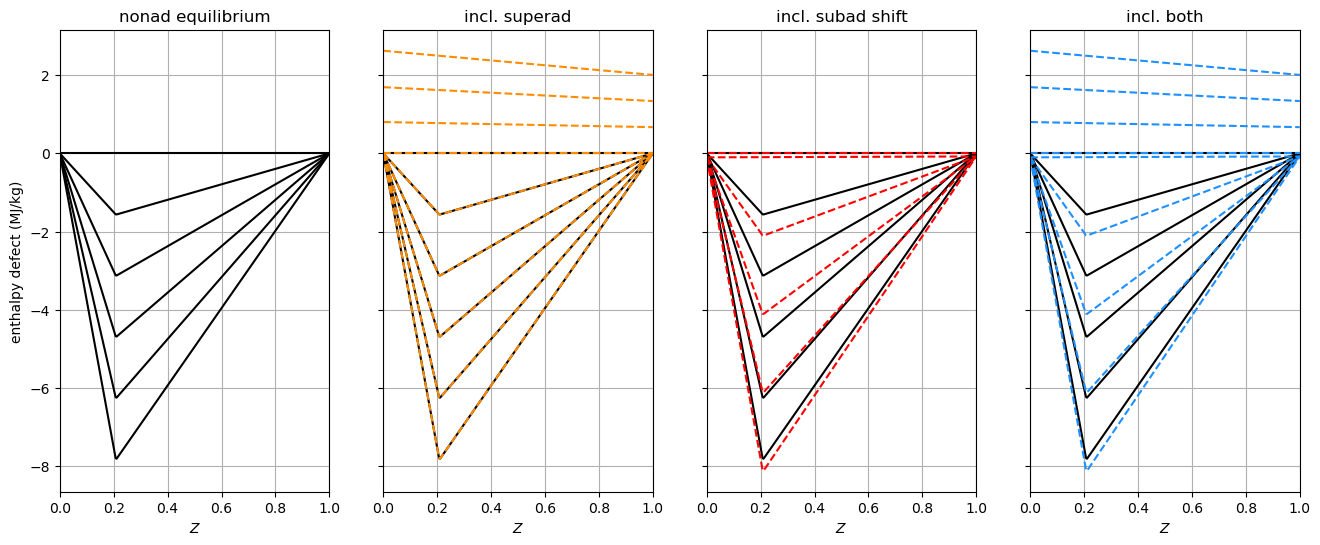

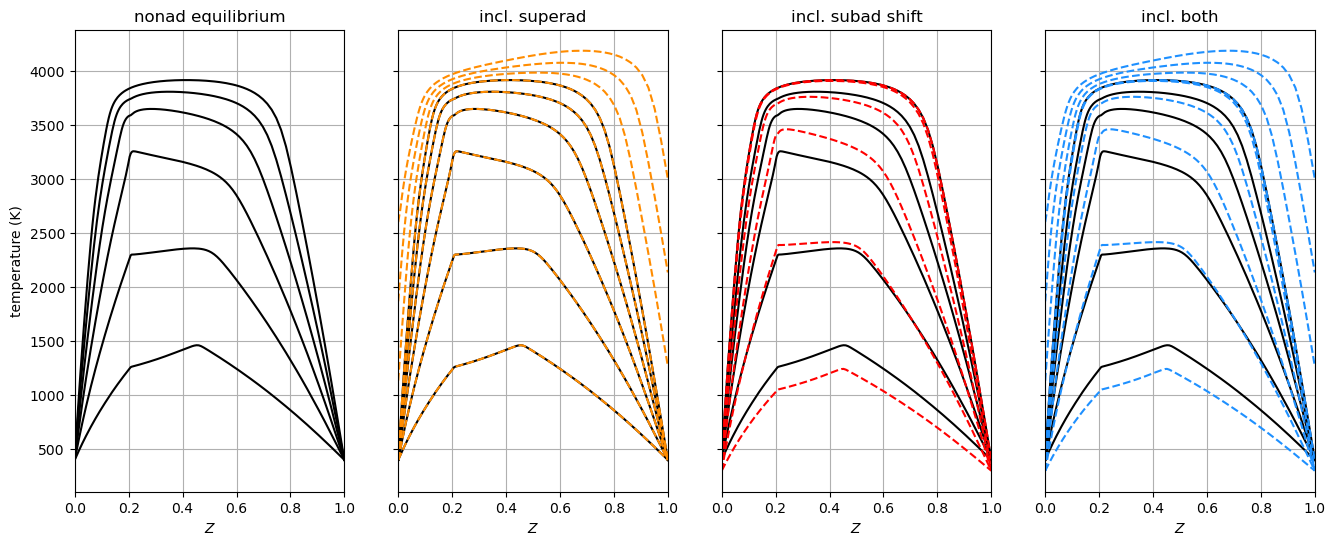

In [26]:
c_orig = 'k'
c_both = 'dodgerblue'
c_sup = 'darkorange'
c_sub = 'r'
lw = 1.5

prop = 'enthalpy_defect'
scl = 1.e-6
fig, axarray = plt.subplots(1, 4, sharex=True, sharey=True)
for i in range(4):
    axarray[i].plot(l_eq.mixture_fraction_values, l_eq[prop] * scl, '-', linewidth=lw, color=c_orig)
axarray[1].plot(l_superad.mixture_fraction_values, l_superad[prop] * scl, '--', linewidth=lw, color=c_sup)
axarray[2].plot(l_subad.mixture_fraction_values, l_subad[prop] * scl, '--', linewidth=lw, color=c_sub)
axarray[3].plot(l_both.mixture_fraction_values, l_both[prop] * scl, '--', linewidth=lw, color=c_both)

axarray[0].set_ylabel('enthalpy defect (MJ/kg)')
axarray[0].set_title('nonad equilibrium')
axarray[1].set_title('incl. superad')
axarray[2].set_title('incl. subad shift')
axarray[3].set_title('incl. both')

for ax in axarray:
    ax.set_xlim([0, 1])
    ax.grid()
    ax.set_xlabel('$Z$')
fig.set_size_inches(16, 6)
plt.show()


prop = 'temperature'
scl = 1.
fig, axarray = plt.subplots(1, 4, sharex=True, sharey=True)
for i in range(4):
    axarray[i].plot(l_eq.mixture_fraction_values, l_eq[prop] * scl, '-', linewidth=lw, color=c_orig)
axarray[1].plot(l_superad.mixture_fraction_values, l_superad[prop] * scl, '--', linewidth=lw, color=c_sup)
axarray[2].plot(l_subad.mixture_fraction_values, l_subad[prop] * scl, '--', linewidth=lw, color=c_sub)
axarray[3].plot(l_both.mixture_fraction_values, l_both[prop] * scl, '--', linewidth=lw, color=c_both)

axarray[0].set_ylabel('temperature (K)')
axarray[0].set_title('nonad equilibrium')
axarray[1].set_title('incl. superad')
axarray[2].set_title('incl. subad shift')
axarray[3].set_title('incl. both')

for ax in axarray:
    ax.set_xlim([0, 1])
    ax.grid()
    ax.set_xlabel('$Z$')
fig.set_size_inches(16, 6)
plt.show()


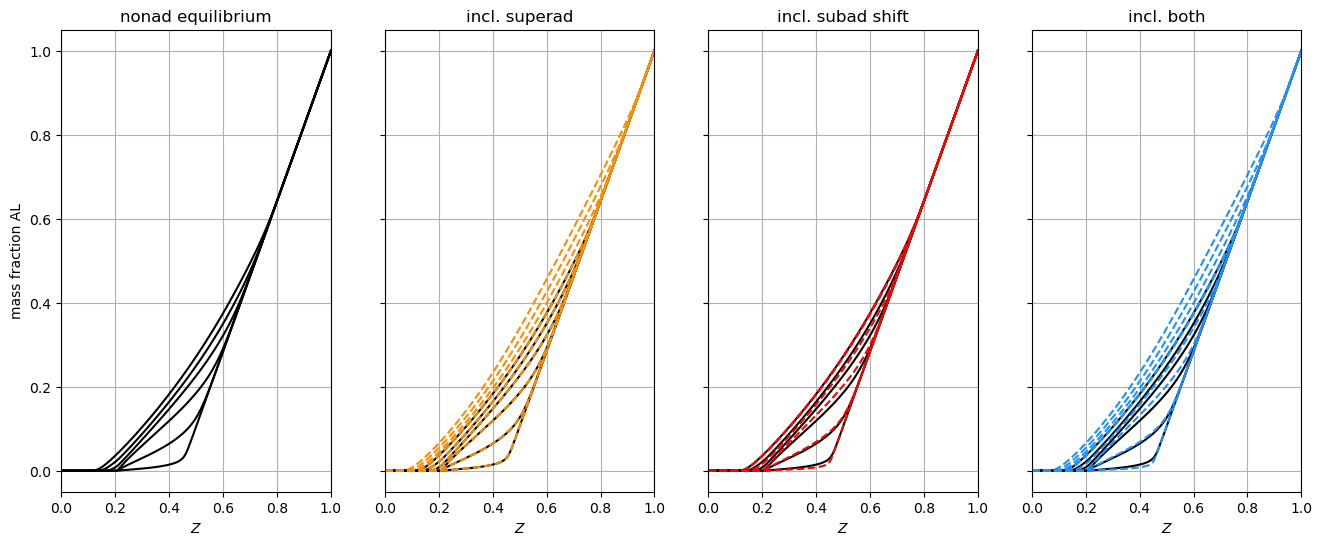

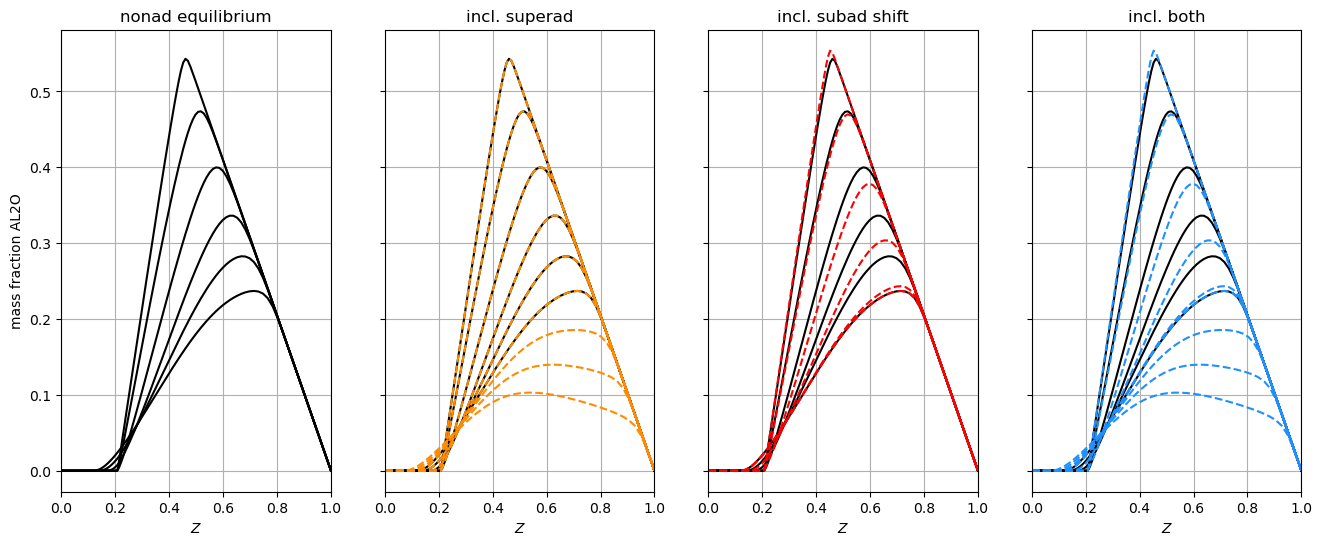

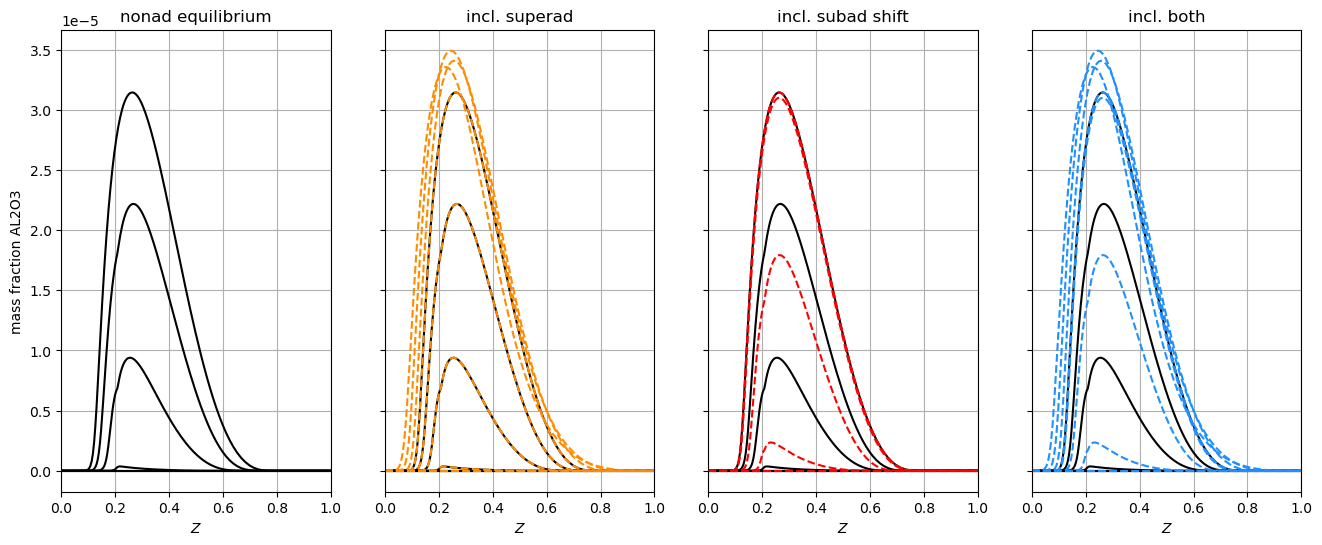

In [27]:
for species in ['AL','AL2O','AL2O3']:
    prop = f'mass fraction {species}'
    scl = 1.
    fig, axarray = plt.subplots(1, 4, sharex=True, sharey=True)
    for i in range(4):
        axarray[i].plot(l_eq.mixture_fraction_values, l_eq[prop] * scl, '-', linewidth=lw, color=c_orig)
    axarray[1].plot(l_superad.mixture_fraction_values, l_superad[prop] * scl, '--', linewidth=lw, color=c_sup)
    axarray[2].plot(l_subad.mixture_fraction_values, l_subad[prop] * scl, '--', linewidth=lw, color=c_sub)
    axarray[3].plot(l_both.mixture_fraction_values, l_both[prop] * scl, '--', linewidth=lw, color=c_both)

    axarray[0].set_ylabel(prop)
    axarray[0].set_title('nonad equilibrium')
    axarray[1].set_title('incl. superad')
    axarray[2].set_title('incl. subad shift')
    axarray[3].set_title('incl. both')

    for ax in axarray:
        ax.set_xlim([0, 1])
        ax.grid()
        ax.set_xlabel('$Z$')
    fig.set_size_inches(16, 6)
    plt.show()


## Nonadiabatic SLFM with heptane chemistry

Superadiabatic and shifted subadiabatic states can also be added to nonadiabatic SLFM libraries. Below we build three nonadiabatic SLFM libraries with various features turned on/off. These features are similar to those displayed for nonadiabatic equilibrium above, but involve a third table dimension of stoichiometric dissipation rate. In this example, we compute libraries for a single stoichiometric dissipation rate so the plots are still two-dimensional. A second difference compared to nonadiabatic equilibrium libraries, is that nonadiabatic SLFM libraries are interpolated onto a structured grid for the stoichiometric enthalpy defect dimension. This effect is shown in the example below.

The first 'nonad SLFM' library does not use any boundary temperature shifts. The smooth enthalpy defect profiles have a single degenerate point at a mixture fraction of zero and one. The adiabatic state is defined by the horizontal line at enthalpy defect of zero.

The second library 'incl. superad' adds 3 superadiabatic profiles to the existing subadiabatic states of 'nonad SLFM'. These are the 3 linear profiles that exist at positive enthalpy defect. The fuel and oxidizer temperatures are shifted by `superad_dT`.

The third library 'incl. both' performs both superadiabatic solutions and shifted subadiabatic solutions. Unlike the analogous equilibrium table, the nonadiabatic states for SLFM get interpolated onto a structured stoichiometric enthalpy defect dimension. This grid is computed using the maximum observed enthalpy defect ranges (positive and negative) relative to the adiabatic state and the `'n_superad'` and `'n_subad'` entries in the specified `n_defect_st` dictionary.


In [28]:
mech = ChemicalMechanismSpec(cantera_input='heptane-liu-hewson-chen-pitsch-highT.yaml', group_name='gas')
pressure = 101325.
air = mech.stream(stp_air=True)
fuel = mech.stream('TPX', (485., pressure, 'NXC7H16:1'))
flamelet_specs = FlameletSpec(mech_spec=mech, oxy_stream=air, fuel_stream=fuel, grid_points=81)

subad_dT = 100.
superad_dT = 100.
n_defect_st = {'n_subad':5, 'n_superad':3}
chivals = np.array([1.e-2])

l_slfm = Library.squeeze(build_nonadiabatic_defect_transient_slfm_library(flamelet_specs, verbose=False,
                                                                          diss_rate_values=chivals, n_defect_st=n_defect_st['n_subad']+1))

l_slfm_superad = Library.squeeze(build_nonadiabatic_defect_transient_slfm_library(flamelet_specs, verbose=False,
                                                                                  diss_rate_values=chivals, n_defect_st=n_defect_st,
                                                                                  superad_dT=superad_dT))

l_slfm_both = Library.squeeze(build_nonadiabatic_defect_transient_slfm_library(flamelet_specs, verbose=False,
                                                                               diss_rate_values=chivals, n_defect_st=n_defect_st,
                                                                               superad_dT=superad_dT, subad_dT=subad_dT))


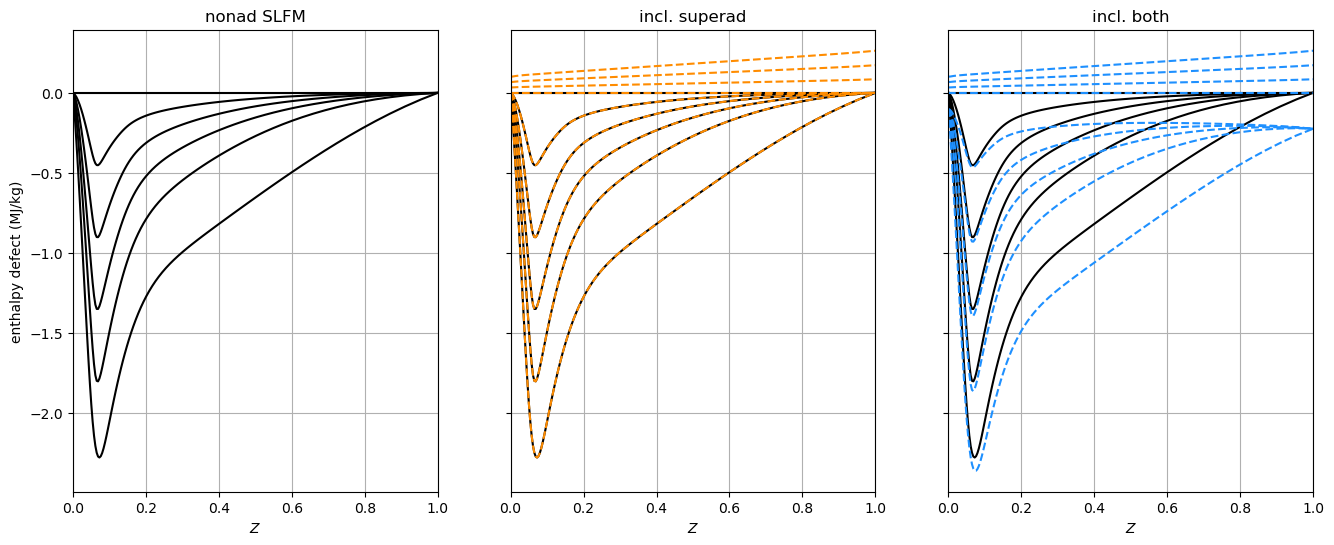

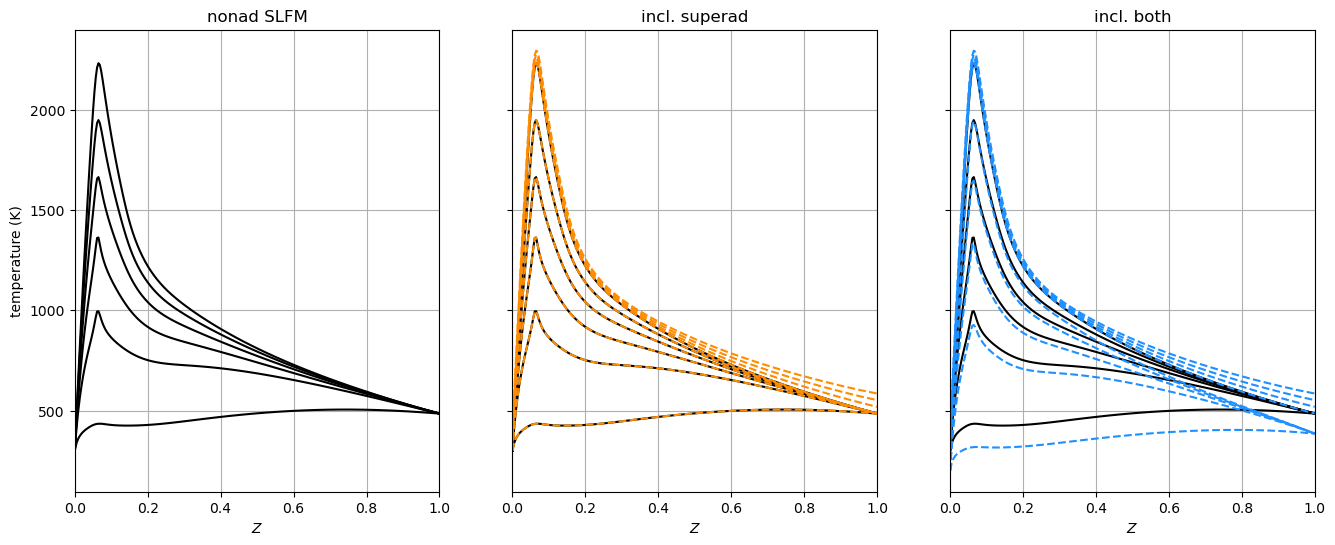

In [29]:
prop = 'enthalpy_defect'
scl = 1.e-6
fig, axarray = plt.subplots(1, 3, sharex=True, sharey=True)
for i in range(3):
    axarray[i].plot(l_slfm.mixture_fraction_values, l_slfm[prop] * scl, '-', linewidth=lw, color=c_orig)
axarray[1].plot(l_slfm_superad.mixture_fraction_values, l_slfm_superad[prop] * scl, '--', linewidth=lw, color=c_sup)
axarray[2].plot(l_slfm_both.mixture_fraction_values, l_slfm_both[prop] * scl, '--', linewidth=lw, color=c_both)

axarray[0].set_ylabel('enthalpy defect (MJ/kg)')
axarray[0].set_title('nonad SLFM')
axarray[1].set_title('incl. superad')
axarray[2].set_title('incl. both')

for ax in axarray:
    ax.set_xlim([0, 1])
    ax.grid()
    ax.set_xlabel('$Z$')
fig.set_size_inches(16, 6)
plt.show()


prop = 'temperature'
scl = 1.
fig, axarray = plt.subplots(1, 3, sharex=True, sharey=True)
for i in range(3):
    axarray[i].plot(l_slfm.mixture_fraction_values, l_slfm[prop] * scl, '-', linewidth=lw, color=c_orig)
axarray[1].plot(l_slfm_superad.mixture_fraction_values, l_slfm_superad[prop] * scl, '--', linewidth=lw, color=c_sup)
axarray[2].plot(l_slfm_both.mixture_fraction_values, l_slfm_both[prop] * scl, '--', linewidth=lw, color=c_both)

axarray[0].set_ylabel('temperature (K)')
axarray[0].set_title('nonad SLFM')
axarray[1].set_title('incl. superad')
axarray[2].set_title('incl. both')

for ax in axarray:
    ax.set_xlim([0, 1])
    ax.grid()
    ax.set_xlabel('$Z$')
fig.set_size_inches(16, 6)
plt.show()
